In [1]:
from torchvision import datasets, transforms

transform = transforms.Compose([transforms.ToTensor()])
train_data = datasets.MNIST(root="~/.cache/", transform=transform, train=True, download=True)
test_data = datasets.MNIST(root="~/.cache/", transform=transform, train=False)
print(train_data[0][0].shape)
print(test_data[0][0].dtype)

torch.Size([1, 28, 28])
torch.float32


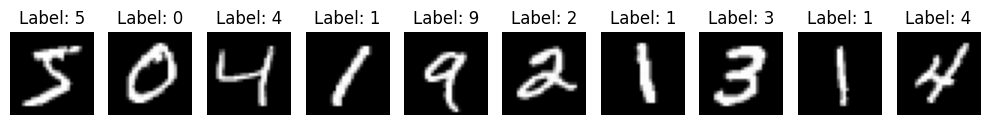

In [2]:
import matplotlib.pyplot as plt

# 遍历前10张图片
fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = train_data[i]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image[0], cmap='gray')  # 显示灰度图像
    # ax.imshow(image.permute(1, 2, 0))
    ax.set_title(f'Label: {label}')  # 显示标签
    ax.axis('off')  # 关闭坐标轴

plt.tight_layout()  # 自动调整子图间的间距
plt.show()

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from vae import VAE

vae = VAE(in_size=28, in_ch=1, chs=[32, 64], latent_dim=2)

x: torch.Tensor = train_data[0][0]
x = x.unsqueeze(0)  # 添加batch维度

x, mu, log_var = vae(x) 
print(x.shape)
print(mu.shape, log_var.shape)

torch.Size([1, 1, 28, 28])
torch.Size([1, 2]) torch.Size([1, 2])


In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vae = VAE(in_size=28, in_ch=1, chs=[64, 128], latent_dim=2).to(device)

dataloader = torch.utils.data.DataLoader(train_data, batch_size=128, shuffle=True, num_workers=4)
optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)
epochs = 50
beta = 1.

vae.train()
for epoch in range(epochs):
    for img, _ in dataloader:
        img = img.to(device)

        x_, mu, log_var = vae(img)
        kld_loss = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())
        loss = F.binary_cross_entropy(x_, img, reduction='sum') + beta * kld_loss
        loss = loss / len(img)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
    if epoch == 0 or (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss.item():.4f}")



Epoch 1/50, Loss: 205.6721
Epoch 10/50, Loss: 157.8229
Epoch 20/50, Loss: 154.0949
Epoch 30/50, Loss: 148.9973
Epoch 40/50, Loss: 156.3201
Epoch 50/50, Loss: 146.0920


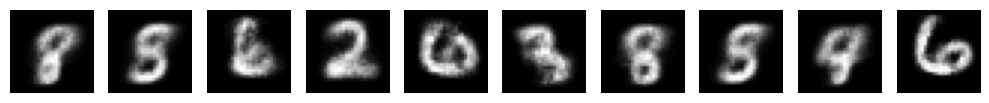

In [5]:
# 生成10个样本
vae.eval()
with torch.inference_mode():
    x = vae.sample(10)
    x = x.cpu()

fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image = x[i]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image[0], cmap='gray')  # 显示灰度图像
    # ax.imshow(image.permute(1, 2, 0))
    ax.axis('off')  # 关闭坐标轴

plt.tight_layout()  # 自动调整子图间的间距
plt.show()

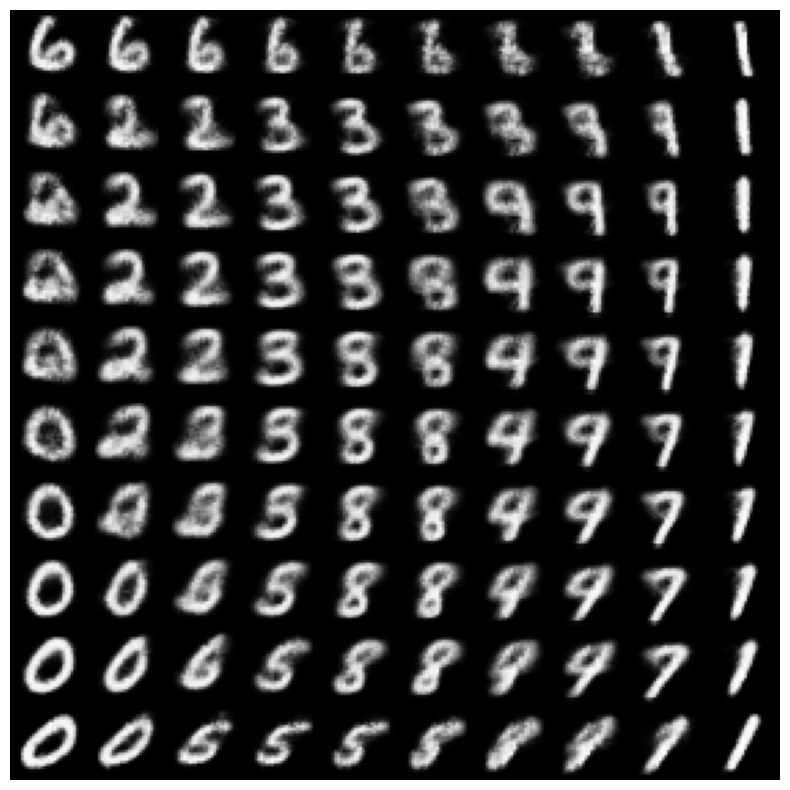

In [6]:
n = 10
digit_size = 28
grid_linspace = torch.linspace(0.05, 0.95, n)
normal = torch.distributions.Normal(0, 1)
grid = normal.icdf(grid_linspace)
grid_x = normal.icdf(torch.linspace(0.05, 0.95, n))
grid_y = normal.icdf(torch.linspace(0.05, 0.95, n))
gx, gy = torch.meshgrid(grid_x, grid_y, indexing='ij')
z_sampled = torch.stack([gx.reshape(-1), gy.reshape(-1)], dim=1)

vae = vae.eval().to(device)
with torch.inference_mode():
    z_sampled = z_sampled.to(device)
    decode = vae.decode(z_sampled)
    decode = decode.cpu() # (n*n, 1, 28, 28)

figure = decode.view(n, n, digit_size, digit_size).permute(0, 2, 1, 3).reshape(n * digit_size, n * digit_size)

plt.figure(figsize=(10, 10))
plt.imshow(figure, cmap="Greys_r")
plt.xticks([])
plt.yticks([])
plt.axis('off');